# Photosynthetic Choice Analysis
This notebook analyzes the results of the metabolic simulations to compare different photosynthetic modes (C3, C4, and intermediates). It generates visualizations for ATP turnover, light uptake, total flux, and biomass production, and predicts the optimal photosynthetic type based on anatomical and biochemical constraints.

## 1. Setup and Imports
Import necessary libraries for data manipulation and visualization, and load the metabolic model.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd
import sys
from Auxiliary import *
from Flux import *
from Visualization import *
import numpy as np
import altair as alt
from cobra.io import read_sbml_model
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
pd.options.mode.chained_assignment = None  # default='warn'
import plotly
plotly.offline.init_notebook_mode(connected=True)

In [2]:
# Load the C4 metabolic model
c4_model = read_sbml_model("../Models/c4_model.xml")

Set parameter Username
Academic license - for non-commercial use only - expires 2027-01-20


## 2. Data Preparation
Load simulation results from CSV files, structure them for analysis, and calculate derived metrics like Quantum Yield.

### 2.1 C3 Scenario Data
Process data where C3 photosynthesis was enforced.

In [3]:
# Load raw C3 scan data
df_C3 = pd.read_csv("../Datasets/Scan_C3_Weighted.csv")

In [4]:
# Structure the data for analysis using helper function
structured_C3 = structure_data(df=df_C3, model=c4_model, filename="../Datasets/C3_Weighted_Structured.csv")

In [5]:
# Calculate Quantum Yield (Carbon Uptake / Total Light Uptake)
structured_C3["Quantum Yield"] = structured_C3["Carbon Uptake"] / (structured_C3["Light Mesophyll"] + structured_C3["Light Bundle Sheath"])

In [6]:
# Select a specific subset of data for standard conditions
selected_C3 = select_data(prepared_df=structured_C3, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

In [7]:
selected_C3

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Nitrate_reductase_B,Nitrite_reductase_M,Nitrite_reductase_B,Glutamine_syn_c_M,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Quantum Yield
5,75.0,1000,0.1,1000.0,20.0,20.0,3.7,350.272727,8.036364,1.0,...,0.0,3.727273,0.0,0.0,0.000000,7.909091,0.0,0.0,0.000000,0.055818
16,75.0,1000,0.2,1000.0,20.0,20.0,3.7,349.833333,8.483333,1.0,...,0.0,3.666667,0.0,0.0,0.000000,7.916667,0.0,0.0,0.000000,0.055817
27,75.0,1000,0.3,1000.0,20.0,20.0,3.7,349.538462,8.861538,1.0,...,0.0,3.692308,0.0,0.0,0.000000,7.923077,0.0,0.0,0.000000,0.055804
38,75.0,1000,0.4,1000.0,20.0,20.0,3.7,349.214286,9.171429,1.0,...,0.0,3.714286,0.0,0.0,0.071429,7.857143,0.0,0.0,0.000000,0.055806
49,75.0,1000,0.5,1000.0,20.0,20.0,3.7,349.000000,9.466667,1.0,...,0.0,3.733333,0.0,0.0,0.000000,7.933333,0.0,0.0,0.000000,0.055793
60,75.0,1000,0.6,1000.0,20.0,20.0,3.7,348.750000,9.712500,1.0,...,0.0,3.687500,0.0,0.0,0.000000,7.937500,0.0,0.0,0.000000,0.055794
71,75.0,1000,0.7,1000.0,20.0,20.0,3.7,348.529412,9.923529,1.0,...,0.0,3.705882,0.0,0.0,0.000000,7.941176,0.0,0.0,0.000000,0.055795
82,75.0,1000,0.8,1000.0,20.0,20.0,3.7,348.388889,10.133333,1.0,...,0.0,3.722222,0.0,0.0,0.000000,7.944444,0.0,0.0,0.000000,0.055785
93,75.0,1000,0.9,1000.0,20.0,20.0,3.7,348.210526,10.278947,1.0,...,0.0,3.684211,0.0,0.0,0.052632,7.894737,0.0,0.0,0.000000,0.055790
104,75.0,1000,1.0,1000.0,20.0,20.0,3.7,348.100000,10.450000,1.0,...,0.0,3.700000,0.0,0.0,0.000000,7.950000,0.0,0.0,0.000000,0.055780


### 2.2 Variable Scenario Data (Free Choice)
Process data where the model could choose between C3 and C4 pathways ("Variable").

In [8]:
# Load raw Variable scan data
df_C4 = pd.read_csv("../Datasets/Scan_Variable_Weighted.csv")

In [9]:
# Structure data and calculate Quantum Yield
structured_C4 = structure_data(df=df_C4, model = c4_model, filename="../Datasets/Variable_Weighted_Structured.csv")
structured_C4["Quantum Yield"] = structured_C4["Carbon Uptake"] / (structured_C4["Light Mesophyll"] + structured_C4["Light Bundle Sheath"])

In [10]:
# Select subset for standard conditions
selected_C4 = select_data(prepared_df=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

selected_C4

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Nitrate_reductase_B,Nitrite_reductase_M,Nitrite_reductase_B,Glutamine_syn_c_M,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Quantum Yield
5,75.0,1000,0.1,1000.0,20.0,20.0,3.7,340.636364,14.481818,1.0,...,0.000000,3.727273,0.000000,0.0,0.0,7.727273,0.0,0.0,0.000000,0.056319
16,75.0,1000,0.2,1000.0,20.0,20.0,3.7,336.000000,17.866667,1.0,...,0.000000,3.666667,0.000000,0.0,0.0,7.666667,0.0,0.0,0.000000,0.056518
27,75.0,1000,0.3,1000.0,20.0,20.0,3.7,330.076923,22.638462,1.0,...,0.000000,3.692308,0.000000,0.0,0.0,7.615385,0.0,0.0,0.000000,0.056703
38,75.0,1000,0.4,1000.0,20.0,20.0,3.7,325.571429,25.628571,1.0,...,0.000000,3.714286,0.000000,0.0,0.0,7.428571,0.0,0.0,0.000000,0.056948
49,75.0,1000,0.5,1000.0,20.0,20.0,3.7,324.666667,26.266667,1.0,...,0.000000,3.733333,0.000000,0.0,0.0,7.466667,0.0,0.0,0.000000,0.056991
60,75.0,1000,0.6,1000.0,20.0,20.0,3.7,320.500000,29.025000,1.0,...,0.000000,3.687500,0.000000,0.0,0.0,7.375000,0.0,0.0,0.000000,0.057221
71,75.0,1000,0.7,1000.0,20.0,20.0,3.7,320.235294,29.235294,1.0,...,0.000000,3.705882,0.000000,0.0,0.0,7.352941,0.0,0.0,0.000000,0.057229
82,75.0,1000,0.8,1000.0,20.0,20.0,3.7,319.666667,29.688889,1.0,...,0.000000,3.722222,0.000000,0.0,0.0,7.333333,0.0,0.0,0.000000,0.057248
93,75.0,1000,0.9,1000.0,20.0,20.0,3.7,318.578947,30.789474,1.0,...,0.047368,3.684211,0.047368,0.0,0.0,7.263158,0.0,0.0,0.047368,0.057246
104,75.0,1000,1.0,1000.0,20.0,20.0,3.7,317.600000,31.550000,1.0,...,0.100000,3.600000,0.100000,0.0,0.0,7.150000,0.0,0.0,0.150000,0.057282


### 2.3 C4-Only Scenario Data
Process data where C4 photosynthesis was enforced.

In [11]:
# Load raw C4-only scan data
df_C4_only = pd.read_csv("../Datasets/Scan_C4_Weighted.csv")

# Structure data
structured_C4_only = structure_data(df=df_C4_only, model = c4_model, filename="../Datasets/C4_Weighted_Structured.csv")

# Calculate Quantum Yield
structured_C4_only["Quantum Yield"] = structured_C4_only["Carbon Uptake"] / (structured_C4_only["Light Mesophyll"] + structured_C4_only["Light Bundle Sheath"])

In [12]:
# Select subset for standard conditions
selected_C4_only = select_data(prepared_df=structured_C4_only, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

selected_C4_only

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Nitrate_reductase_B,Nitrite_reductase_M,Nitrite_reductase_B,Glutamine_syn_c_M,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Quantum Yield
5,75.0,1000,0.1,1000.0,20.0,20.0,3.7,227.454545,90.909091,1.0,...,0.000000,3.727273,0.000000,0.0,0.0,4.000000,0.0,0.0,0.000000,0.062821
16,75.0,1000,0.2,1000.0,20.0,20.0,3.7,169.416667,166.666667,1.0,...,0.000000,3.666667,0.000000,0.0,0.0,3.583333,0.0,0.0,0.500000,0.059509
27,75.0,1000,0.3,1000.0,20.0,20.0,3.7,145.384615,192.530769,1.0,...,0.000000,3.692308,0.000000,0.0,0.0,3.538462,0.0,0.0,0.507692,0.059186
38,75.0,1000,0.4,1000.0,20.0,20.0,3.7,130.928571,189.371429,1.0,...,0.000000,3.714286,0.000000,0.0,0.0,3.571429,0.0,0.0,0.485714,0.062441
49,75.0,1000,0.5,1000.0,20.0,20.0,3.7,130.333333,189.766667,1.0,...,0.000000,3.733333,0.000000,0.0,0.0,3.533333,0.0,0.0,0.500000,0.062480
60,75.0,1000,0.6,1000.0,20.0,20.0,3.7,130.187500,189.712500,1.0,...,0.000000,3.687500,0.000000,0.0,0.0,3.562500,0.0,0.0,0.487500,0.062520
71,75.0,1000,0.7,1000.0,20.0,20.0,3.7,122.823529,192.211765,1.0,...,0.000000,3.705882,0.000000,0.0,0.0,3.529412,0.0,0.0,0.494118,0.063485
82,75.0,1000,0.8,1000.0,20.0,20.0,3.7,123.111111,189.333333,1.0,...,0.000000,3.722222,0.000000,0.0,0.0,3.555556,0.0,0.0,0.488889,0.064011
93,75.0,1000,0.9,1000.0,20.0,20.0,3.7,120.315789,185.400000,1.0,...,0.000000,3.684211,0.000000,0.0,0.0,3.526316,0.0,0.0,0.473684,0.065420
104,75.0,1000,1.0,1000.0,20.0,20.0,3.7,120.450000,185.050000,1.0,...,0.000000,3.700000,0.000000,0.0,0.0,3.550000,0.0,0.0,0.500000,0.065466


## 3. Comparative Analysis: Enforced C3 vs. Free Choice
Compare metabolic costs and outputs between the enforced C3 scenario and the scenario where the model optimizes for the best pathway (often resulting in C4 or intermediates).

- Visualize the ATP maintenance costs associated with different photosynthetic modes.
- Visualize the total photon uptake required.
- Visualize the total metabolic flux (proxy for enzyme investment/cost).

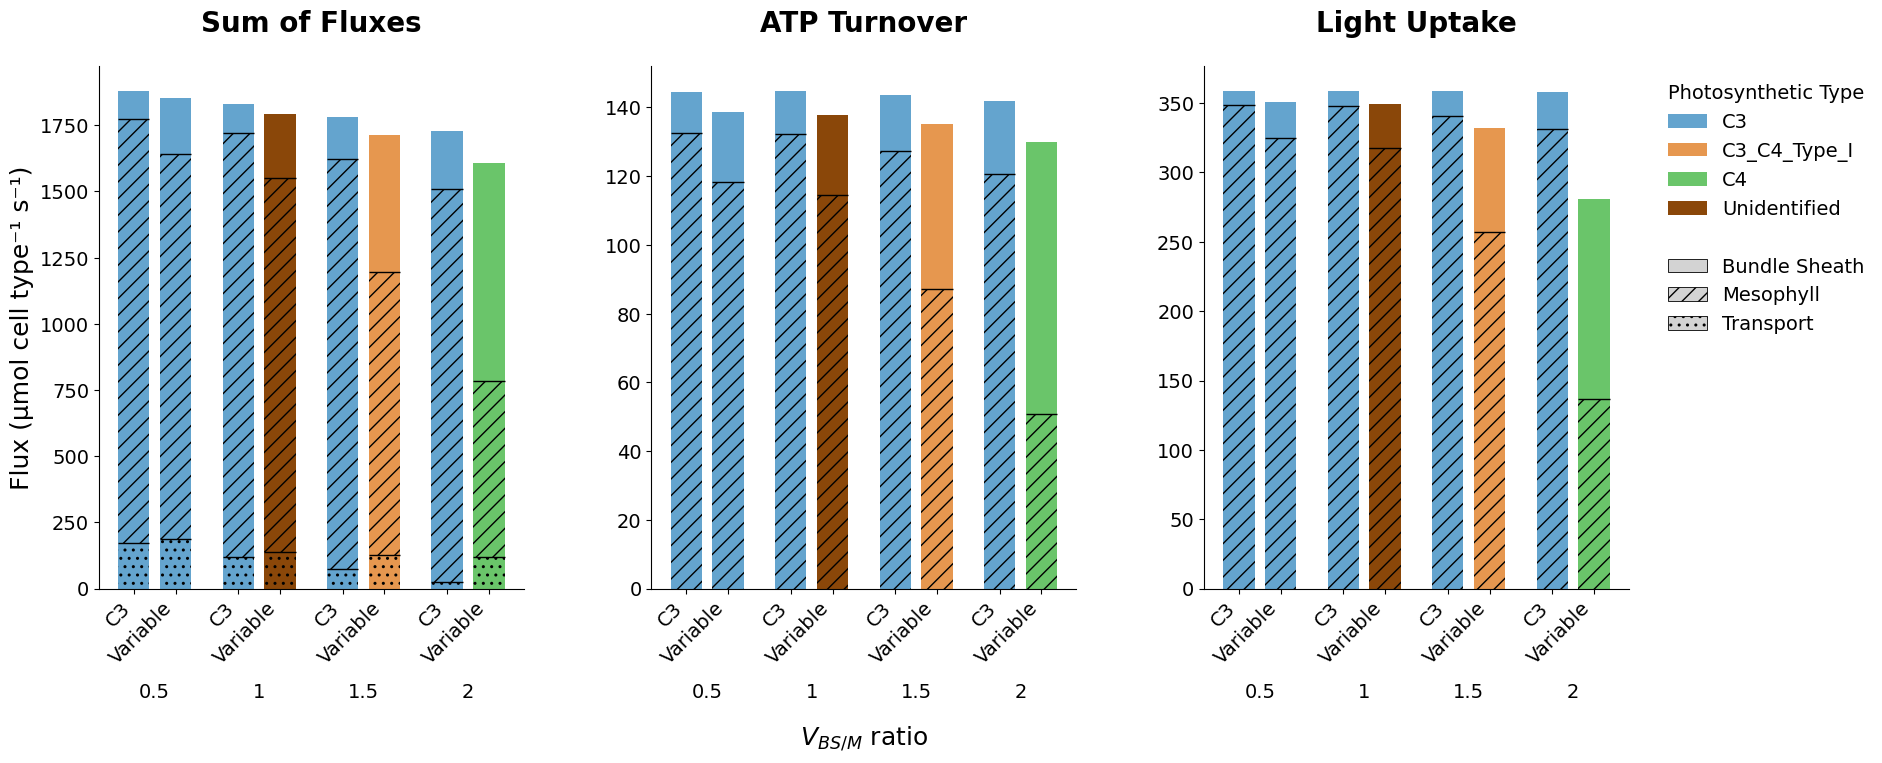

In [13]:
# Subplots, Bundle Sheath and Mesophyll comparison
metabolic_comparison_subplots(df_C3=structured_C3, df_C4=structured_C4,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

### 3.1 Biomass Production
Visualize the biomass production rate.

In [14]:
# Compare Biomass Production
comparison_Biomass_barplots_3D(df_C3=structured_C3, df_C4=structured_C4, df_C4_only=structured_C4_only,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

alt.FacetChart(...)

### 3.2 Nitrogen assimilation


In [15]:
def nitrogen_comparison_subplots(df_C3, df_C4, PPFD, Vc_Vo, CO2, PC_BS, NH3):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), sharey=False)
    volume_ratios = [0.5, 1, 1.5, 2]
    color_map = {'C3': '#64a4ceff', 'C3_C4_Type_I': '#e6954cfb', 'C4': '#69c569fe', 'Unidentified': '#884405fb'}
    
    def get_data():
        s_C3 = select_data(prepared_df=df_C3, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
        s_C4 = select_data(prepared_df=df_C4, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
        s_C3 = s_C3[s_C3.V_BS_M.isin(volume_ratios)].copy()
        s_C4 = s_C4[s_C4.V_BS_M.isin(volume_ratios)].copy()
        s_C3['Classification'] = "C3"
        s_C4['Classification'] = "Variable"
        return pd.concat([s_C3, s_C4])

    df_combined = get_data()

    # Summing GS compartments for Mesophyll (M) and Bundle Sheath (B)
    df_combined['GS_Total_M'] = df_combined[["Glutamine_syn_c_M", "Glutamine_syn_m_M", "Glutamine_syn_p_M"]].sum(axis=1)
    df_combined['GS_Total_B'] = df_combined[["Glutamine_syn_c_B", "Glutamine_syn_m_B", "Glutamine_syn_p_B"]].sum(axis=1)

    plot_configs = [
        (ax1, "Nitrate Reductase (NR)", "Nitrate_reductase_M", "Nitrate_reductase_B"),
        (ax2, "Glutamine Synthetase (GS)", "GS_Total_M", "GS_Total_B")
    ]

    for ax, title, col_meso, col_bs in plot_configs:
        tick_positions = []
        tick_labels = []
        bar_width = 0.22
        group_gap = 0.06

        for i, vol in enumerate(volume_ratios):
            vol_data = df_combined[df_combined['V_BS_M'] == vol]
            for j, cls in enumerate(["C3", "Variable"]):
                row = vol_data[vol_data['Classification'] == cls]
                if row.empty: continue
                
                base_color = color_map.get(row['Photosynthesis'].iloc[0], 'black')
                pos = i + (j * (bar_width + group_gap))
                tick_positions.append(pos)
                tick_labels.append(cls)

                v_m = row[col_meso].iloc[0]
                v_b = row[col_bs].iloc[0]

                # Stacked bars
                ax.bar(pos, v_m, width=bar_width, color=base_color, hatch='//', edgecolor='white', label='Mesophyll' if i==0 and j==0 else "")
                ax.bar(pos, v_b, bottom=v_m, width=bar_width, color=base_color, edgecolor='white', label='Bundle Sheath' if i==0 and j==0 else "")

        ax.set_title(title, fontsize=14, fontweight='bold', pad=25)
        ax.set_ylabel("Flux (µmol cell type⁻¹ s⁻¹)", fontsize=11, fontweight='bold')
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)

        for i, vol in enumerate(volume_ratios):
            group_center = i + (bar_width + group_gap) / 2
            ax.text(group_center, -0.12, f"V={vol}", transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=10, fontweight='bold')

    # Legend
    fill_elements = [
        Patch(facecolor='darkgray', edgecolor='black', label='Bundle Sheath'),
        Patch(facecolor='darkgray', edgecolor='black', hatch='//', label='Mesophyll')
    ]
    photo_elements = [Patch(facecolor=c, edgecolor='black', label=l) for l, c in color_map.items()]
    
    ax2.legend(handles=photo_elements + [Patch(alpha=0, label="")] + fill_elements, 
               title="Photosynthetic Type / Compartment", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.25, wspace=0.3, right=0.8)
    plt.show()

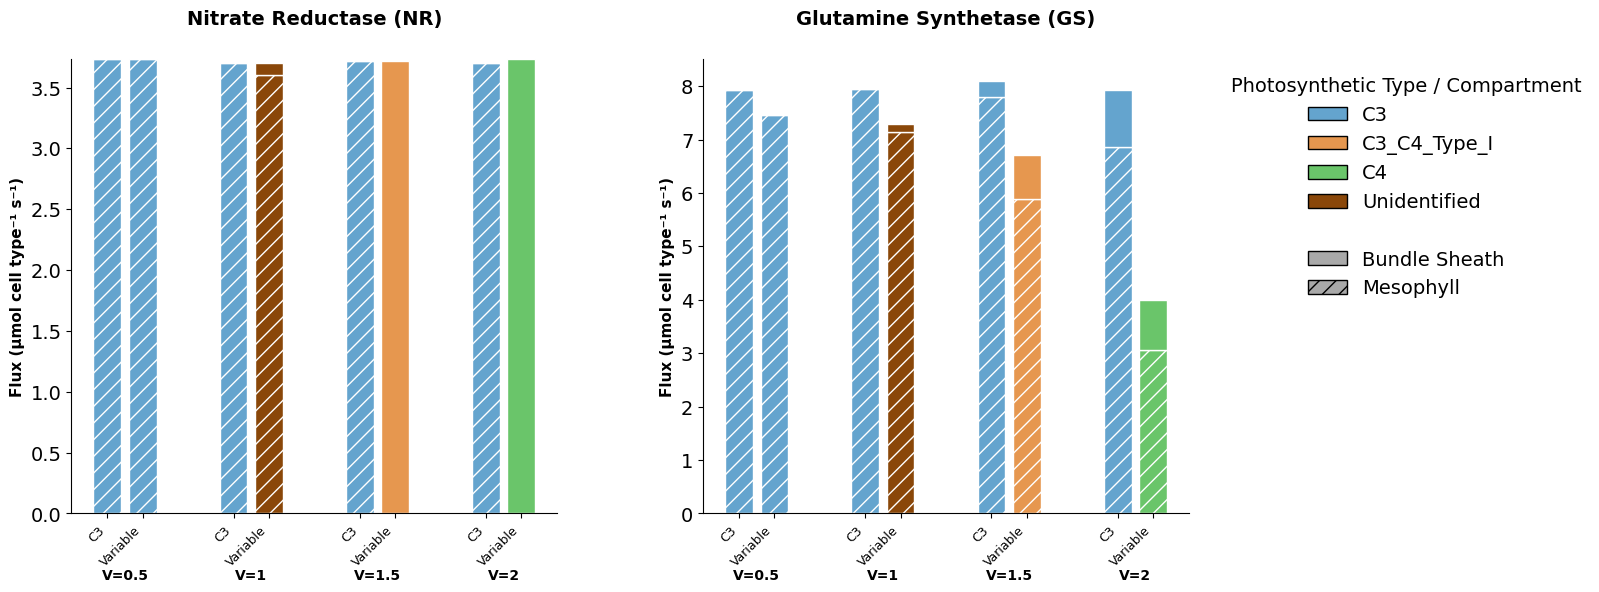

In [16]:
nitrogen_comparison_subplots(df_C3=structured_C3, df_C4=structured_C4,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

In [17]:
def nitrogen_linear_plot(df_C4, PPFD, Vc_Vo, CO2, PC_BS, NH3):

    s_C4 = select_data(prepared_df=df_C4, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
    
    volume_ratios = [0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2]
    df_plot = s_C4[s_C4.V_BS_M.isin(volume_ratios)].sort_values('V_BS_M').copy()

    # Totals
    df_plot['GS_Total_M'] = df_plot[["Glutamine_syn_c_M", "Glutamine_syn_m_M", "Glutamine_syn_p_M"]].sum(axis=1)
    df_plot['GS_Total_B'] = df_plot[["Glutamine_syn_c_B", "Glutamine_syn_m_B", "Glutamine_syn_p_B"]].sum(axis=1)
    df_plot['NR_Total'] = df_plot["Nitrate_reductase_M"] + df_plot["Nitrate_reductase_B"]
    df_plot['GS_Total'] = df_plot['GS_Total_M'] + df_plot['GS_Total_B']

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    c_meso = '#2ecc71' 
    c_bs = '#3498db'   
    c_total = 'black'

    # Nitrate Reductase (NR)
    ax1.plot(df_plot['V_BS_M'], df_plot['Nitrate_reductase_M'], label='Mesophyll', marker='o', color=c_meso, linestyle='--')
    ax1.plot(df_plot['V_BS_M'], df_plot['Nitrate_reductase_B'], label='Bundle Sheath', marker='o', color=c_bs, linestyle='--')
    ax1.plot(df_plot['V_BS_M'], df_plot['NR_Total'], label='Total NR', marker='s', color=c_total, linewidth=2)
    ax1.set_title("Nitrate Reductase (NR) Flux", fontweight='bold')

    # Glutamine Synthetase (GS)
    ax2.plot(df_plot['V_BS_M'], df_plot['GS_Total_M'], label='Mesophyll', marker='o', color=c_meso, linestyle='--')
    ax2.plot(df_plot['V_BS_M'], df_plot['GS_Total_B'], label='Bundle Sheath', marker='o', color=c_bs, linestyle='--')
    ax2.plot(df_plot['V_BS_M'], df_plot['GS_Total'], label='Total GS', marker='s', color=c_total, linewidth=2)
    ax2.set_title("Glutamine Synthetase (GS) Flux", fontweight='bold')

    for ax in [ax1, ax2]:
        ax.set_xlabel("V_BS / V_M Ratio", fontsize=10)
        ax.set_ylabel("Flux (µmol cell type⁻¹ s⁻¹)", fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(frameon=False)
        ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()

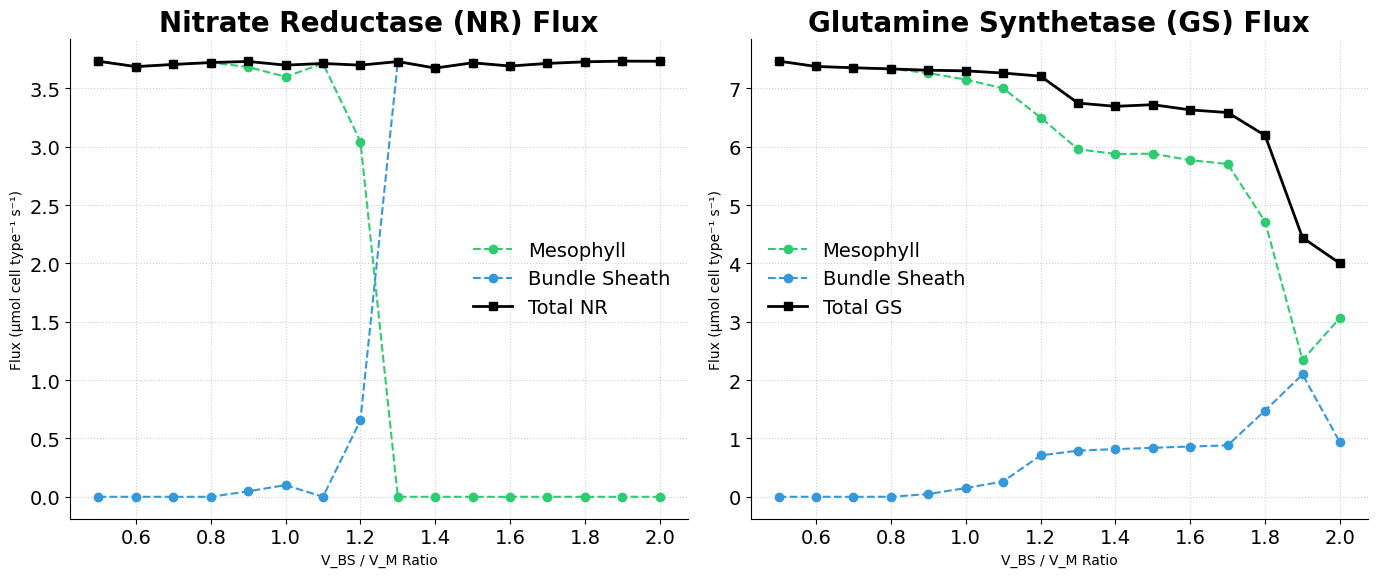

In [18]:
nitrogen_linear_plot(df_C4=structured_C4,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

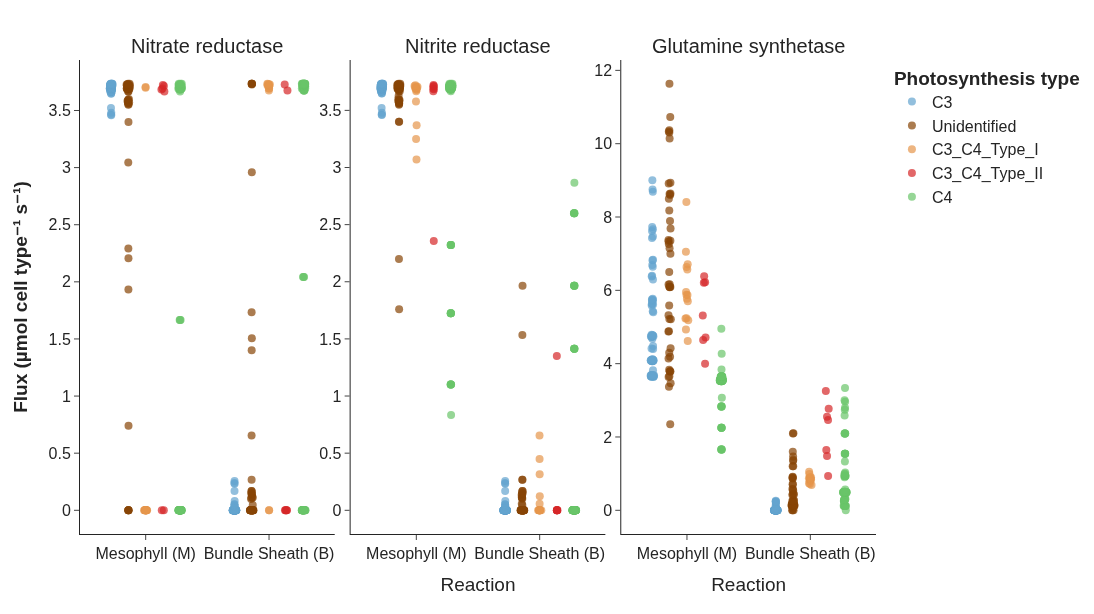

In [19]:
import plotly.express as px
import pandas as pd

custom_colors = {
    'C3': '#64a4ce', 
    'C3_C4_Type_I': '#e6954c', 
    'C3_C4_Type_II': '#d62728',
    'C4': '#69c569', 
    'Unidentified': '#884405'
}

# -------------------- NITRATE --------------------
df1 = structured_C4.melt(
    id_vars=['Photosynthesis'],
    value_vars=['Nitrate_reductase_M', 'Nitrate_reductase_B'],
    var_name='Reaction',
    value_name='Flux'
)

df1['Reaction'] = df1['Reaction'].replace({
    'Nitrate_reductase_M': 'Mesophyll (M)',
    'Nitrate_reductase_B': 'Bundle Sheath (B)'
})

df1["Process"] = "Nitrate Reductase"

# -------------------- NITRITE --------------------
df2 = structured_C4.melt(
    id_vars=['Photosynthesis'],
    value_vars=['Nitrite_reductase_M', 'Nitrite_reductase_B'],
    var_name='Reaction',
    value_name='Flux'
)

df2['Reaction'] = df2['Reaction'].replace({
    'Nitrite_reductase_M': 'Mesophyll (M)',
    'Nitrite_reductase_B': 'Bundle Sheath (B)'
})

df2["Process"] = "Nitrite Reductase"

# -------------------- GLUTAMINE --------------------
structured_C4['GS_Total_M'] = structured_C4[
    ["Glutamine_syn_c_M", "Glutamine_syn_m_M", "Glutamine_syn_p_M"]
].sum(axis=1)

structured_C4['GS_Total_B'] = structured_C4[
    ["Glutamine_syn_c_B", "Glutamine_syn_m_B", "Glutamine_syn_p_B"]
].sum(axis=1)

df3 = structured_C4.melt(
    id_vars=['Photosynthesis'],
    value_vars=['GS_Total_M', 'GS_Total_B'],
    var_name='Reaction',
    value_name='Flux'
)

df3['Reaction'] = df3['Reaction'].replace({
    'GS_Total_M': 'Mesophyll (M)',
    'GS_Total_B': 'Bundle Sheath (B)'
})

df3["Process"] = "Glutamine (GS Total)"

df_all = pd.concat([df1, df2, df3], ignore_index=True)

fig = px.strip(
    df_all,
    x="Reaction",
    y="Flux",
    color="Photosynthesis",
    facet_col="Process",  
    stripmode="group",
    color_discrete_map=custom_colors,
    category_orders={
        "Photosynthesis": ["C3", "Unidentified", "C3_C4_Type_I", "C3_C4_Type_II", "C4"],
        "Reaction": ["Mesophyll (M)", "Bundle Sheath (B)"],
        "Process": ["Nitrate Reductase", "Nitrite Reductase", "Glutamine (GS Total)"]
    },
    template="simple_white"
)

fig.update_traces(marker=dict(size=8, opacity=0.7))

fig.update_layout(
    width=1600,
    height=600,
    xaxis_title="",
    yaxis_title="<b>Flux (µmol cell type⁻¹ s⁻¹)</b>",
    legend_title="<b>Photosynthesis type</b>",
    font=dict(size=16)
)
fig.update_yaxes(matches=None, showticklabels=True)

name_map = {
    "Nitrate Reductase": "Nitrate reductase",
    "Nitrite Reductase": "Nitrite reductase",
    "Glutamine (GS Total)": "Glutamine synthetase"
}

fig.for_each_annotation(lambda a: a.update(
    text=name_map.get(a.text.split("=")[-1], a.text),
    font=dict(size=20)   
))

fig.write_image( "../Images/N_plots.svg", width=1600, height=600)

fig.show()

## 4. Reaction Flux Analysis
Analyze how specific reaction fluxes change with anatomical parameters ($V_{BS/M}$) and photorespiratory conditions ($V_c/V_o$).

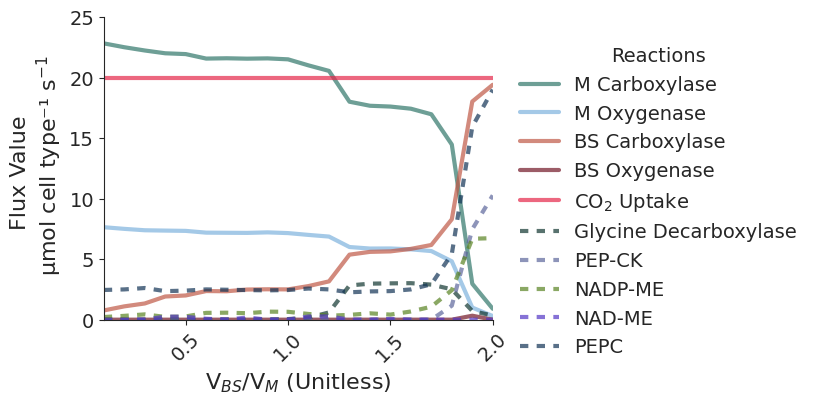

In [20]:
# Line plot of key reactions vs Volume Ratio
g = reaction_lineplot_VRatio(data=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

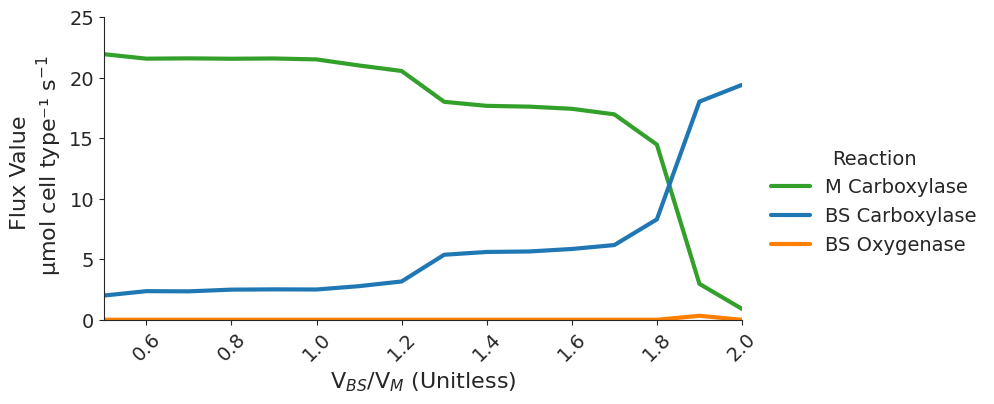

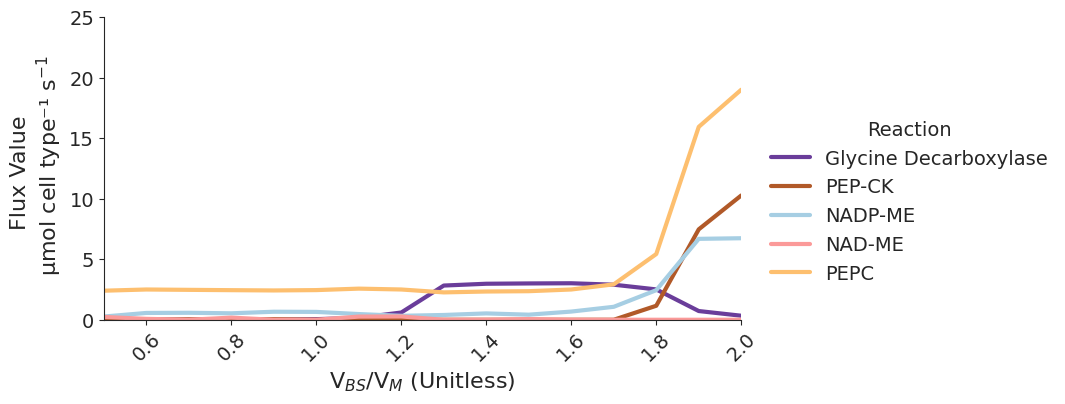

In [21]:
# Split line plot of key reactions vs Volume Ratio
g1, g2 = reaction_lineplot_VRatio_split(data=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

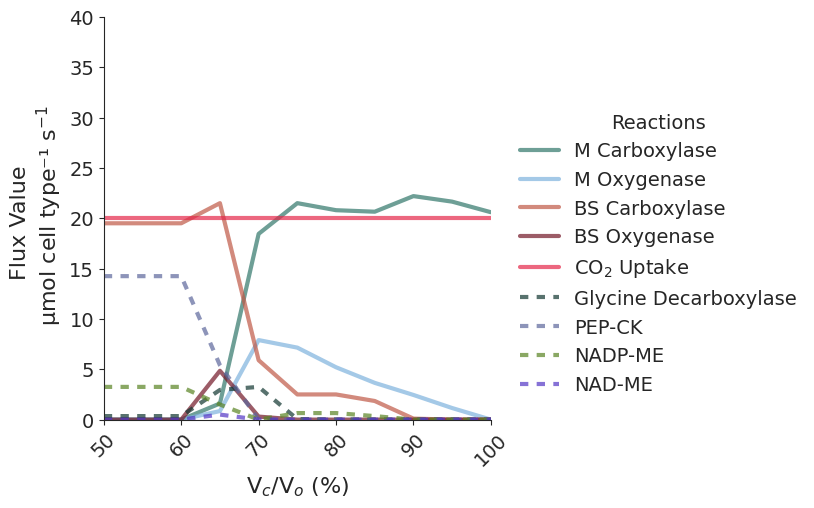

In [22]:
# Line plot of key reactions vs Vc/Vo ratio
reaction_lineplot_Vc_Vo(data=structured_C4, PPFD=1000, V_BS_M = 1 ,CO2=20, PC_BS=1, NH3 = 1000)

## 5. Photosynthetic Type Prediction (Bubble Plots)
Generate bubble plots to visualize the distribution of Rubisco activity between Mesophyll and Bundle Sheath cells, effectively predicting the photosynthetic type (C3, C3-C4, C4) across the parameter space of anatomy ($V_{BS/M}$) and photorespiration ($V_c/V_o$).

In [23]:
def plot_flux_solutions_bubbles_V2(structured_C4, PPFD=1000, CO2=40, PC_BS=1, NH3=1000, 
                                desired_max_marker_px=18, output_svg="Bubble_Unsuberised.svg",
                                use_jitter=False):
    """
    Generates a bubble plot visualizing Rubisco flux distribution across different photosynthetic types.
    
    Parameters:
    - structured_C4: DataFrame containing structured simulation results.
    - PPFD, CO2, PC_BS, NH3: Environmental and physiological parameters.
    - desired_max_marker_px: Maximum size of bubbles in pixels.
    - output_svg: Filename for saving the plot.
    - use_jitter: Boolean to add jitter to x-axis for better visibility of overlapping points.
    """

    data = select_data_3D(prepared_df=structured_C4, PPFD=PPFD, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
    
    # Filter out V_BS_M < 0.2
    data = data[data['V_BS_M'] >= 0.2].copy()

    VM_list = [1 / (1 + v) for v in data.V_BS_M]
    VBS_list = [v / (1 + v) for v in data.V_BS_M]
    data['BS_Carboxylation'] = data['BS_Rubisco'] + data['BS_Rubisco_C4']
    data['M_Carboxylation'] = data['M_Rubisco']
    # data['BS_Oxygenation'] = data['BS Oxygenase'] 
    # data['M_Oxygenation'] = data['M Oxygenase']

    for n in range(len(data)):
        data['M_Rubisco'].iloc[n] = data['M_Rubisco'].iloc[n] * VM_list[n]
        data['BS_Rubisco'].iloc[n] = data['BS_Rubisco'].iloc[n] * VBS_list[n]
        data['BS_Rubisco_C4'].iloc[n] = data['BS_Rubisco_C4'].iloc[n] * VBS_list[n]
        data['Glycine Decarboxylase'].iloc[n] = data['Glycine Decarboxylase'].iloc[n] * VBS_list[n]
        data['PEP-CK'].iloc[n] = data['PEP-CK'].iloc[n] * VBS_list[n]
        data['NADP-ME'].iloc[n] = data['NADP-ME'].iloc[n] * VBS_list[n]
        data['NAD-ME'].iloc[n] = data['NAD-ME'].iloc[n] * VBS_list[n]
        data['BS_Carboxylation'].iloc[n] = data['BS_Carboxylation'].iloc[n] * VBS_list[n]
        data['M_Carboxylation'].iloc[n] = data['M_Carboxylation'].iloc[n] * VM_list[n]
        # data['BS_Oxygenation'].iloc[n] = data['BS_Oxygenation'].iloc[n] * VBS_list[n]
        # data['M_Oxygenation'].iloc[n] = data['M_Oxygenation'].iloc[n] * VM_list[n]

    df = pd.DataFrame(data)
    photo_intermediates = ["C3", "C3_C4_Type_I", "C3_C4_Type_II", "Unidentified", "C4"]
    df_filtered = df.loc[df['Photosynthesis'].isin(photo_intermediates)]

    df_melted = df_filtered.melt(
        id_vars=['Vc_Vo', 'V_BS_M', "Photosynthesis"], 
        value_vars=['M_Carboxylation', 'BS_Carboxylation'], 
        var_name='Enzyme',
        value_name='Z'
    )

    df_melted = df_melted.rename(columns={"Z": "Flux Values"})
    df_melted["Enzyme"] = df_melted.Enzyme.replace({
        "M_Carboxylation": "Mesophyll Carboxylation", 
        "BS_Carboxylation": "Bundle Sheath Carboxylation"
    })
    df_melted["Photosynthesis"] = df_melted.Photosynthesis.replace({
        "C3_C4_Type_II": "C3-C4 Type II", 
        "C3_C4_Type_I": "C3-C4 Type I"
    })
    df_melted["Photosynthesis"] = df_melted.Photosynthesis.replace({
        "C3-C4 Type I": "C3-C4",
        "C3-C4 Type II": "C3-C4"
    })
    df_melted["Photosynthesis"] = pd.Categorical(
        df_melted["Photosynthesis"],
        categories=["C3", "Unidentified", "C3-C4", "C4"],
        ordered=True
    )

    if use_jitter:
        np.random.seed(0)
        jitter_mag = 0.01  
        df_melted['V_BS_M_display'] = df_melted['V_BS_M'] + np.random.uniform(-jitter_mag, jitter_mag, size=len(df_melted))
        x_col = 'V_BS_M_display'
    else:
        x_col = 'V_BS_M'

    enzyme_colors = {
        'Mesophyll Carboxylation': '#06402B', 
        'Bundle Sheath Carboxylation': '#e6b705'
    }
    custom_colors = ['#e6b705', "#06402B"]

    # ---------- CONTROL MARKER SIZE (sizeref) ----------
    max_val = df_melted['Flux Values'].abs().max() if len(df_melted)>0 else 1.0

    desired_px = desired_max_marker_px
    sizeref = 3.0 * max_val / (desired_px ** 2 + 1e-12)

    fig = px.scatter(
        df_melted,
        y='Vc_Vo',
        x=x_col,
        size='Flux Values',
        size_max=desired_px,
        color='Enzyme',
        color_discrete_sequence=custom_colors,
        facet_col='Photosynthesis',
        category_orders={"Photosynthesis": ["C3", "Unidentified", "C3-C4", "C4"]},
        color_discrete_map=enzyme_colors,
        facet_col_spacing=0.01,   
        height=420,
        width=1600  
    )

    # Apply sizeref and marker styling to all marker traces 
    fig.update_traces(
        marker=dict(sizemode='area', sizeref=sizeref, line=dict(width=0, color='black')),
        selector=dict(mode='markers')
    )

    fig.update_xaxes(range=[0.15, 2.05], dtick=0.1, tick0=0.2, tickformat=".1f", tickangle=-45)
    
    ncols = len(["C3", "Unidentified", "C3-C4", "C4"])
    for col in range(1, ncols + 1):
        fig.update_xaxes(title_text="<b>V<sub>BS/M</sub></b>", col=col)

    fig.update_layout(
        title=dict(text="", x=0.5, xanchor='center', font=dict(size=20, family='Arial')),
        yaxis_title="<b>V<sub>c</sub> / V<sub>o</sub></b>",
        xaxis_title="<b>V<sub>BS/M</sub></b>",
        legend_title=dict(text="<b>Enzymes</b>"),
        font=dict(size=14, family='Arial'),  
        plot_bgcolor='white',
        margin=dict(l=70, r=180, t=50, b=80),  
        legend=dict(
            orientation='v',  
            yanchor='middle',  
            y=0.5,  
            x=1.02,  
            xanchor='left',  
            font=dict(size=14, family='Arial')
        )
    )

    fig.for_each_annotation(lambda a: a.update(font=dict(size=16, family='Arial')))
    fig.update_xaxes(tickfont=dict(size=11, family='Arial'))
    fig.update_yaxes(tickfont=dict(size=11, family='Arial'))
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))

    new_titles = {"C3": "<b>C<sub>3</sub></b>", "Unidentified": "<b>Unidentified</b>",
                  "C3-C4": "<b>C<sub>3</sub>-C<sub>4</sub></b>", "C4": "<b>C<sub>4</sub></b>"}
    fig.for_each_annotation(lambda a: a.update(text=new_titles.get(a.text, a.text)))

    fig.update_yaxes(mirror=True, ticks='outside', showline=True, linecolor='black',
                     gridcolor='#e8e8e8', griddash="dash", autorange="reversed",
                     title_font=dict(size=15, family='Arial'))
    fig.update_xaxes(mirror=True, ticks='outside', showline=True, linecolor='black',
                     gridcolor='#e8e8e8', griddash="dash",
                     title_font=dict(size=15, family='Arial'))

    expected_facets = ["C3", "Unidentified", "C3-C4", "C4"]
    present_facets = set(df_melted["Photosynthesis"].unique())
    for facet in expected_facets:
        if facet not in present_facets:
            col_num = expected_facets.index(facet) + 1
            fig.add_trace(
                go.Scatter(
                    y=[np.nan], x=[np.nan],
                    mode='markers',
                    marker=dict(opacity=0),
                    showlegend=False
                ), row=1, col=col_num
            )
    fig.update_xaxes(dtick=0.1)

    fig.update_xaxes(
    range=[0.15, 2.05],
    tickvals=np.arange(0.2, 2.01, 0.2),   
    ticktext=[f"{v:.1f}" for v in np.arange(0.2, 2.01, 0.2)],
    tickangle=-45,
    tickformat=".1f"
    )
    
    for col in range(1, len(expected_facets) + 1):
        fig.add_hline(
            y=75, 
            line_dash="solid", 
            line_color="red", 
            line_width=2,
            opacity=0.35, 
            layer="below",
            row=1, 
            col=col
        )

    # --- ADD BACKGROUND REGIONS ---
    # C3 (Column 1): 0.5 to 1.1 - Light Blue
    fig.add_shape(
        type="rect",
        x0=0.5, x1=1.1,
        y0=0, y1=1,
        xref="x", yref="paper",
        fillcolor="rgba(100, 164, 206, 50)", opacity=0.5,
        layer="below", line_width=0
    )

    # C3-C4 (Column 3): 0.7 to 1.1 - Light Orange
    fig.add_shape(
        type="rect",
        x0=0.7, x1=1.7,
        y0=0, y1=1,
        xref="x3", yref="paper",
        fillcolor="rgba(230, 149, 77, 50)", opacity=.5,
        layer="below", line_width=0
    )

    # C4 (Column 4): 1.2 to 2.0 - Light Green
    fig.add_shape(
        type="rect",
        x0=1.2, x1=2.0,
        y0=0, y1=1,
        xref="x4", yref="paper",
        fillcolor="rgba(107, 197, 107, 50)", opacity=0.5,
        layer="below", line_width=0
    )

    #fig.write_image(output_svg, width=1400, height=420)
    #fig.show()
    return fig

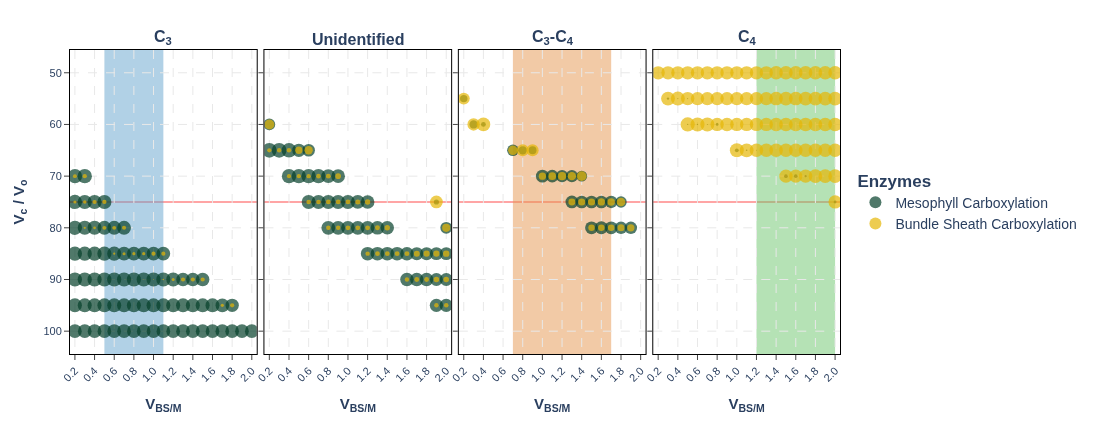

In [24]:
# Generate the bubble plot
plot_flux_solutions_bubbles_V2(structured_C4, CO2=20, PC_BS=1, NH3=1000 )

## Comparison without the plasmodesmatal weight

In [25]:
# Load raw Variable scan data
df_C4_noplasmodesmatalw = pd.read_csv("../Datasets/Scan_Variable_Weighted_noplasmodesmatalw.csv")
# Structure data and calculate Quantum Yield
structured_C4_noplasmodesmatalw = structure_data(df=df_C4_noplasmodesmatalw, model = c4_model, filename="../Datasets/Variable_Weighted_Structured_df_C4_noplasmodesmatalw.csv")
structured_C4_noplasmodesmatalw["Quantum Yield"] = structured_C4_noplasmodesmatalw["Carbon Uptake"] / (structured_C4_noplasmodesmatalw["Light Mesophyll"] + structured_C4_noplasmodesmatalw["Light Bundle Sheath"])

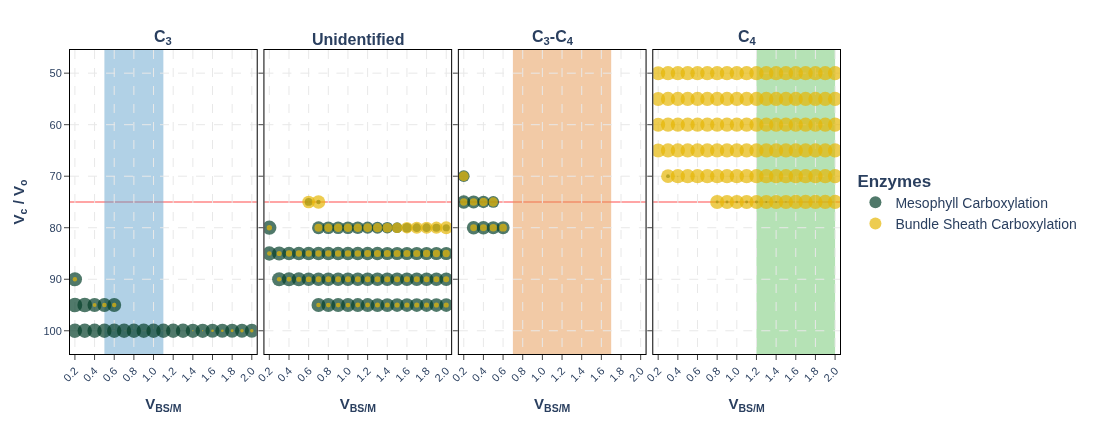

In [26]:
# Generate the bubble plot
plot_flux_solutions_bubbles_V2(structured_C4_noplasmodesmatalw, CO2=20, PC_BS=1, NH3=1000 )